Guía 9: Predicción Inicial de Desempeño (`guia_09_prediccion_inicial.ipynb`)

**Proyecto:** HRTech People Analytics (`Analytics_performance`)  
**Dataset utilizado:** `datos/procesados/dataset_limpio_guia02.csv` (evaluaciones trimestrales `2025-Q3` a `2026-Q2`)

## Ficha de formulación predictiva

| Campo | Definición |
|---|---|
| **Pregunta predictiva** | ¿Cuál será el `puntaje_desempeno` de cada colaborador en el siguiente trimestre de evaluación (`2026-Q2`) a partir de su historial previo y variables laborales? |
| **Decisión empresarial apoyada** | Identificar de forma anticipada caídas de desempeño para priorizar planes de acompañamiento, capacitación y retención de talento antes del cierre trimestral. |
| **Tipo de problema** | Regresión supervisada (variable objetivo numérica continua). |
| **Variable objetivo ($y$)** | `puntaje_desempeno` (escala 0–100; rango observado `62.48` a `95.60`). |
| **Variables predictoras ($X$)** | 8 variables sin fuga temporal: `lag_1_puntaje`, `media_hist_puntaje`, `lag_1_ausencias`, `lag_1_horas_extra`, `lag_1_horas_capacitacion`, `antiguedad`, `salario_mensual` y `trimestre`. |
| **Variables excluidas por fuga (*data leakage*)** | Componentes del cálculo del mismo trimestre (`productividad_pct`, `calidad_trabajo_pct`, `cumplimiento_objetivos_pct`, `asistencia_pct`, `nivel_desempeno`, `nivel_desempeno_calculado`), variables de encuesta recolectadas en junio 2026 (`indice_satisfaccion_promedio`, `respuestas_*`) y resultados posteriores (`riesgo_rotacion`, `estado_laboral`). |
| **Estrategia de validación** | Corte cronológico estricto: entrenamiento con `2025-Q4` y `2026-Q1` (hasta `2026-03-31`) y prueba con `2026-Q2` (`2026-06-30`). |
| **Métricas de evaluación** | MAE (principal), RMSE y $R^2$, comparando siempre contra un baseline de media (`DummyRegressor`). |

## Parte A. Preparar el entorno y librerías

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Detectar la raíz del proyecto automáticamente (funciona desde notebooks/ o desde la raíz)
BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RUTA_DATASET = BASE_DIR / "datos" / "procesados" / "dataset_limpio_guia02.csv"
if not RUTA_DATASET.exists():
    RUTA_DATASET = Path("dataset_limpio_guia02.csv")

RUTA_SALIDA_PRED = BASE_DIR / "datos" / "procesados" / "predicciones_guia09.csv"
RUTA_SALIDA_METRICAS = BASE_DIR / "documentos" / "metricas_guia09.csv"

RUTA_SALIDA_PRED.parent.mkdir(parents=True, exist_ok=True)
RUTA_SALIDA_METRICAS.parent.mkdir(parents=True, exist_ok=True)

print("Raíz del proyecto:", BASE_DIR)
print("Dataset encontrado:", RUTA_DATASET.exists(), "->", RUTA_DATASET)

Raíz del proyecto: c:\Users\PC-GOMEZ\Downloads\ITCA\IA_BIGDATA\SEMANA16\HRTechPeopleAnalytics_ProyectoFinal
Dataset encontrado: True -> c:\Users\PC-GOMEZ\Downloads\ITCA\IA_BIGDATA\SEMANA16\HRTechPeopleAnalytics_ProyectoFinal\datos\procesados\dataset_limpio_guia02.csv


## Parte B. Cargar y verificar el histórico del proyecto

Se carga `dataset_limpio_guia02.csv`, se convierte `fecha_evaluacion` a formato fecha y se deduplica por `(empleado_id, periodo)` conservando el registro más reciente/corregido para obtener un panel balanceado de **40 colaboradores × 4 trimestres (160 registros)**.

In [3]:
df_raw = pd.read_csv(RUTA_DATASET)
df_raw["fecha_evaluacion"] = pd.to_datetime(df_raw["fecha_evaluacion"])

print("Registros originales:", len(df_raw))
duplicados = df_raw.duplicated(subset=["empleado_id", "periodo"]).sum()
print("Registros duplicados por (empleado_id, periodo):", duplicados)

# Deduplicar conservando el registro más reciente / corrección
df = (
    df_raw.sort_values(["empleado_id", "fecha_evaluacion", "registro_id"])
          .drop_duplicates(subset=["empleado_id", "periodo"], keep="last")
          .sort_values(["fecha_evaluacion", "empleado_id"])
          .reset_index(drop=True)
)

print("Registros tras deduplicar:", len(df))
print("Rango temporal:", df["fecha_evaluacion"].min().date(), "->", df["fecha_evaluacion"].max().date())
print("\nConteo de registros por periodo:")
print(df["periodo"].value_counts().sort_index())

cols_clave = [
    "empleado_id", "periodo", "fecha_evaluacion", "puntaje_desempeno",
    "ausencias_dias", "horas_extra", "horas_capacitacion", "antiguedad", "salario_mensual"
]
print("\nNulos en columnas clave:")
print(df[cols_clave].isnull().sum())
print("\nEstadísticas descriptivas de puntaje_desempeno:")
print(df["puntaje_desempeno"].describe().round(2))

df[cols_clave].head()

Registros originales: 168
Registros duplicados por (empleado_id, periodo): 8
Registros tras deduplicar: 160
Rango temporal: 2025-09-30 -> 2026-06-30

Conteo de registros por periodo:
periodo
2025-Q3    40
2025-Q4    40
2026-Q1    40
2026-Q2    40
Name: count, dtype: int64

Nulos en columnas clave:
empleado_id           0
periodo               0
fecha_evaluacion      0
puntaje_desempeno     0
ausencias_dias        1
horas_extra           0
horas_capacitacion    1
antiguedad            0
salario_mensual       0
dtype: int64

Estadísticas descriptivas de puntaje_desempeno:
count    160.00
mean      82.67
std        6.82
min       62.48
25%       77.86
50%       83.62
75%       87.60
max       95.60
Name: puntaje_desempeno, dtype: float64


,empleado_id,periodo,fecha_evaluacion,puntaje_desempeno,ausencias_dias,horas_extra,horas_capacitacion,antiguedad,salario_mensual
0,EMP001,2025-Q3,2025-09-30,77.55,1.0,9,12.0,3,1400.0
1,EMP002,2025-Q3,2025-09-30,84.31,1.0,5,4.0,1,1450.0
2,EMP003,2025-Q3,2025-09-30,73.94,2.0,6,17.0,2,1100.0
3,EMP004,2025-Q3,2025-09-30,81.23,3.0,9,9.0,5,1650.0
4,EMP005,2025-Q3,2025-09-30,80.41,1.0,9,11.0,4,1200.0


## Parte C. Explorar antes de predecir

Evolución trimestral del puntaje de desempeño:
                   mean   std    min    max
fecha_evaluacion                           
2025-09-30        83.48  6.52  71.50  94.16
2025-12-31        83.12  6.34  68.84  95.47
2026-03-31        82.01  6.88  64.90  95.22
2026-06-30        82.08  7.60  62.48  95.60


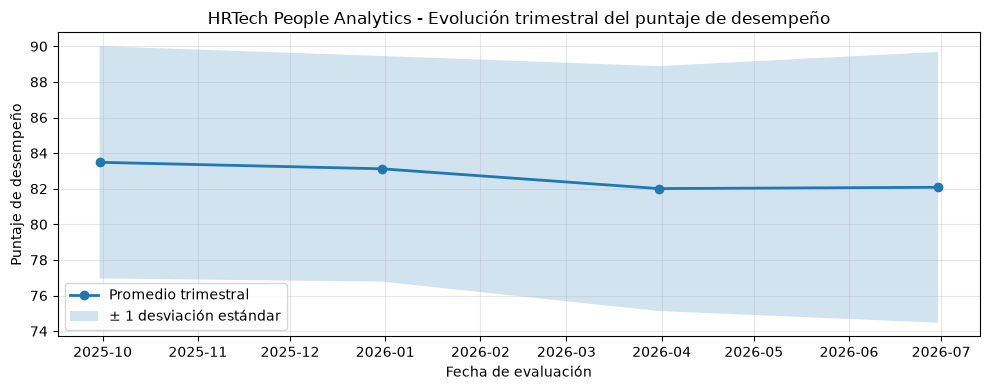


Puntaje promedio según modalidad:
modalidad
Híbrida       84.89
Presencial    81.57
Remota        81.88
Name: puntaje_desempeno, dtype: float64

Puntaje promedio según riesgo de rotación:
riesgo_rotacion
Alto     76.05
Bajo     84.62
Medio    78.33
Name: puntaje_desempeno, dtype: float64


In [4]:
resumen_periodo = df.groupby("fecha_evaluacion")["puntaje_desempeno"].agg(["mean", "std", "min", "max"])
print("Evolución trimestral del puntaje de desempeño:")
print(resumen_periodo.round(2))

plt.figure(figsize=(10, 4))
plt.plot(resumen_periodo.index, resumen_periodo["mean"], marker="o", linewidth=2, label="Promedio trimestral")
plt.fill_between(
    resumen_periodo.index,
    resumen_periodo["mean"] - resumen_periodo["std"],
    resumen_periodo["mean"] + resumen_periodo["std"],
    alpha=0.2,
    label="± 1 desviación estándar"
)
plt.title("HRTech People Analytics - Evolución trimestral del puntaje de desempeño")
plt.xlabel("Fecha de evaluación")
plt.ylabel("Puntaje de desempeño")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nPuntaje promedio según modalidad:")
print(df.groupby("modalidad")["puntaje_desempeno"].mean().round(2))

print("\nPuntaje promedio según riesgo de rotación:")
print(df.groupby("riesgo_rotacion")["puntaje_desempeno"].mean().round(2))

### Documentación exploratoria (Parte C)

- **Patrón 1 (Tendencia y dispersión trimestral):** El puntaje promedio de desempeño presenta una leve disminución progresiva entre `2025-Q3` (`83.48`) y `2026-Q1` (`82.01`), estabilizándose en `2026-Q2` (`82.08`), mientras que la dispersión aumenta de `6.52` a `7.60` y el mínimo cae de `71.50` a `62.48`.
- **Patrón 2 (Diferencias por modalidad y riesgo):** Los colaboradores en modalidad `Híbrida` muestran un promedio más alto (`84.89`) frente a `Remota` (`81.88`) y `Presencial` (`81.57`). Además, quienes presentan `riesgo_rotacion` `Alto` tienen un desempeño promedio notablemente menor (`76.05`) que los de riesgo `Bajo` (`84.62`).
- **Hipótesis validable:** El historial previo de desempeño de cada colaborador (`lag_1_puntaje` y su promedio histórico acumulado `media_hist_puntaje`), junto con su carga laboral previa (`lag_1_ausencias`, `lag_1_horas_extra`, `lag_1_horas_capacitacion`) y variables contractuales (`antiguedad`, `salario_mensual`), permitirá predecir el `puntaje_desempeno` del siguiente trimestre con un MAE sustancialmente menor al del baseline de media.

## Parte D. Crear características históricas sin fuga de datos

Todas las variables históricas se calculan agrupando por `empleado_id` en orden cronológico y aplicando `.shift(1)` para garantizar que el modelo utilice **únicamente información de trimestres anteriores**.

In [5]:
df = df.sort_values(["empleado_id", "fecha_evaluacion"]).reset_index(drop=True)

# Rezagos de 1 trimestre por colaborador (sin información del trimestre actual)
df["lag_1_puntaje"] = df.groupby("empleado_id")["puntaje_desempeno"].shift(1)
df["lag_1_ausencias"] = df.groupby("empleado_id")["ausencias_dias"].shift(1)
df["lag_1_horas_extra"] = df.groupby("empleado_id")["horas_extra"].shift(1)
df["lag_1_horas_capacitacion"] = df.groupby("empleado_id")["horas_capacitacion"].shift(1)

# Media móvil / acumulada histórica hasta el trimestre anterior
df["media_hist_puntaje"] = (
    df.groupby("empleado_id")["puntaje_desempeno"]
      .transform(lambda s: s.shift(1).expanding().mean())
)

# Variable calendario del periodo
df["trimestre"] = df["fecha_evaluacion"].dt.quarter

features = [
    "lag_1_puntaje",
    "media_hist_puntaje",
    "lag_1_ausencias",
    "lag_1_horas_extra",
    "lag_1_horas_capacitacion",
    "antiguedad",
    "salario_mensual",
    "trimestre"
]

# Eliminar únicamente filas iniciales sin historial suficiente (2025-Q3) o nulos en rezagos
df_modelo = (
    df.dropna(subset=features + ["puntaje_desempeno"])
      .sort_values(["fecha_evaluacion", "empleado_id"])
      .reset_index(drop=True)
)

print("Filas originales deduplicadas:", len(df))
print("Filas disponibles para modelado:", len(df_modelo))
print("Distribución por periodo en df_modelo:")
print(df_modelo["periodo"].value_counts().sort_index())

Filas originales deduplicadas: 160
Filas disponibles para modelado: 119
Distribución por periodo en df_modelo:
periodo
2025-Q4    40
2026-Q1    39
2026-Q2    40
Name: count, dtype: int64


## Parte E. Definir X e y (verificación anti-fuga)

In [6]:
X = df_modelo[features]
y = df_modelo["puntaje_desempeno"]

# Comprobación explícita: ninguna columna en X pertenece a métricas del mismo periodo ni a encuestas futuras
variables_prohibidas = {
    "puntaje_desempeno", "productividad_pct", "calidad_trabajo_pct",
    "cumplimiento_objetivos_pct", "asistencia_pct", "indice_satisfaccion_promedio"
}
assert variables_prohibidas.isdisjoint(set(X.columns)), "¡Se detectó una variable con fuga de datos en X!"
print("Verificación anti-fuga aprobada. Variables predictoras:", list(X.columns))
X.head()

Verificación anti-fuga aprobada. Variables predictoras: ['lag_1_puntaje', 'media_hist_puntaje', 'lag_1_ausencias', 'lag_1_horas_extra', 'lag_1_horas_capacitacion', 'antiguedad', 'salario_mensual', 'trimestre']


,lag_1_puntaje,media_hist_puntaje,lag_1_ausencias,lag_1_horas_extra,lag_1_horas_capacitacion,antiguedad,salario_mensual,trimestre
0,77.55,77.55,1.0,9.0,12.0,3,1400.0,4
1,84.31,84.31,1.0,5.0,4.0,1,1450.0,4
2,73.94,73.94,2.0,6.0,17.0,2,1100.0,4
3,81.23,81.23,3.0,9.0,9.0,5,1650.0,4
4,80.41,80.41,1.0,9.0,11.0,4,1200.0,4


## Parte F. Dividir entrenamiento y prueba (corte cronológico estricto)

Al tratarse de un panel trimestral donde todos los colaboradores se evalúan en la misma fecha de cierre, el corte cronológico se realiza por fecha:
- **Entrenamiento:** `2025-Q4` y `2026-Q1` (hasta `2026-03-31`, 79 registros).
- **Prueba:** `2026-Q2` (`2026-06-30`, 40 registros).

Así se garantiza que **todas las fechas de prueba sean estrictamente posteriores** a las de entrenamiento.

In [7]:
fecha_corte = df_modelo["fecha_evaluacion"].max()

mask_train = df_modelo["fecha_evaluacion"] < fecha_corte
mask_test = df_modelo["fecha_evaluacion"] == fecha_corte

X_train, y_train = X.loc[mask_train], y.loc[mask_train]
X_test, y_test = X.loc[mask_test], y.loc[mask_test]
df_test = df_modelo.loc[mask_test].copy()

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)
print("Última fecha entrenamiento:", df_modelo.loc[mask_train, "fecha_evaluacion"].max().date())
print("Primera fecha prueba:      ", df_modelo.loc[mask_test, "fecha_evaluacion"].min().date())
assert df_modelo.loc[mask_train, "fecha_evaluacion"].max() < df_modelo.loc[mask_test, "fecha_evaluacion"].min()

Entrenamiento: (79, 8)
Prueba: (40, 8)
Última fecha entrenamiento: 2026-03-31
Primera fecha prueba:       2026-06-30


## Parte G. Construir un baseline

In [8]:
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
pred_baseline = baseline.predict(X_test)

mae_base = mean_absolute_error(y_test, pred_baseline)
rmse_base = mean_squared_error(y_test, pred_baseline) ** 0.5
r2_base = r2_score(y_test, pred_baseline)

print(f"Baseline MAE : {mae_base:.2f}")
print(f"Baseline RMSE: {rmse_base:.2f}")
print(f"Baseline R²  : {r2_base:.4f}")

Baseline MAE : 6.00
Baseline RMSE: 7.52
Baseline R²  : -0.0034


## Parte H. Entrenar el primer modelo (Regresión Lineal)

In [9]:
modelo = LinearRegression()
modelo.fit(X_train, y_train)
pred = modelo.predict(X_test)

mae = mean_absolute_error(y_test, pred)
rmse = mean_squared_error(y_test, pred) ** 0.5
r2 = r2_score(y_test, pred)

print(f"Modelo MAE : {mae:.2f}")
print(f"Modelo RMSE: {rmse:.2f}")
print(f"Modelo R²  : {r2:.4f}")

Modelo MAE : 3.52
Modelo RMSE: 4.34
Modelo R²  : 0.6667


## Parte I. Comparar baseline y modelo

In [10]:
comparacion = pd.DataFrame({
    "Modelo": ["Baseline media", "Regresión lineal"],
    "MAE": [round(mae_base, 4), round(mae, 4)],
    "RMSE": [round(rmse_base, 4), round(rmse, 4)],
    "R2": [round(r2_base, 4), round(r2, 4)]
})

mejora_mae = ((mae_base - mae) / mae_base) * 100
print(f"Mejora del MAE frente al baseline: {mejora_mae:.2f}%")
comparacion

Mejora del MAE frente al baseline: 41.36%


,Modelo,MAE,RMSE,R2
0,Baseline media,6.0009,7.5219,-0.0034
1,Regresión lineal,3.5186,4.3351,0.6667


### Interpretación de la comparación

La regresión lineal reduce el error absoluto medio (MAE) de **6.00** puntos en el baseline a **3.52** puntos (**41.36% de mejora**), y disminuye el RMSE de **7.52** a **4.34** puntos, alcanzando un $R^2$ de **0.6667** en el trimestre de prueba (`2026-Q2`).  
Un margen promedio de ±3.52 puntos en una escala de 0 a 100 es útil como **alerta temprana** para gestión de talento, aunque todavía no es suficientemente preciso para decisiones individuales sensibles (como bonos o desvinculaciones) sin revisión humana.

## Parte J. Visualizar valores reales y predicciones

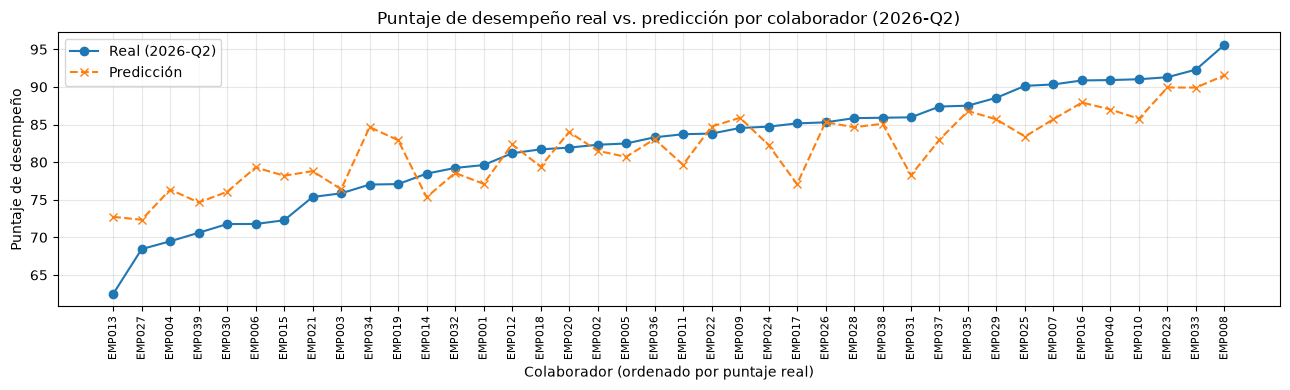

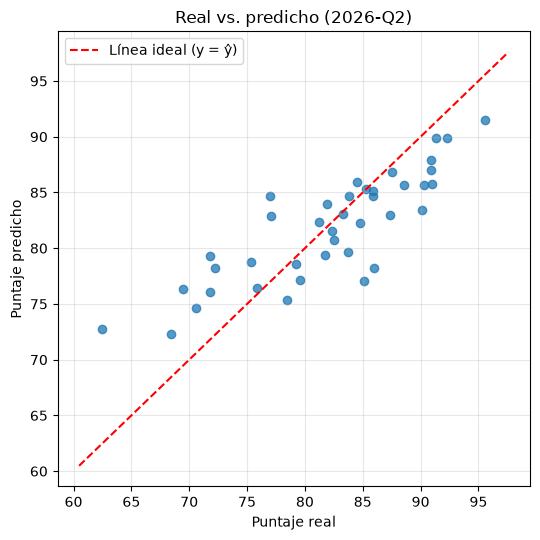

In [11]:
# Gráfico 1: Comparación por colaborador en el trimestre de prueba (2026-Q2)
orden = np.argsort(y_test.values)
empleados_ord = df_test["empleado_id"].values[orden]

plt.figure(figsize=(13, 4))
plt.plot(range(len(y_test)), y_test.values[orden], marker="o", label="Real (2026-Q2)")
plt.plot(range(len(pred)), pred[orden], marker="x", linestyle="--", label="Predicción")
plt.xticks(range(len(y_test)), empleados_ord, rotation=90, fontsize=8)
plt.title("Puntaje de desempeño real vs. predicción por colaborador (2026-Q2)")
plt.xlabel("Colaborador (ordenado por puntaje real)")
plt.ylabel("Puntaje de desempeño")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Gráfico 2: Dispersión Real vs. Predicho
plt.figure(figsize=(5.5, 5.5))
plt.scatter(y_test, pred, alpha=0.75)
lim_min = min(y_test.min(), pred.min()) - 2
lim_max = max(y_test.max(), pred.max()) + 2
plt.plot([lim_min, lim_max], [lim_min, lim_max], linestyle="--", color="red", label="Línea ideal (y = ŷ)")
plt.xlabel("Puntaje real")
plt.ylabel("Puntaje predicho")
plt.title("Real vs. predicho (2026-Q2)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Parte K. Analizar residuos

In [12]:
resultados = pd.DataFrame({
    "empleado_id": df_test["empleado_id"].values,
    "fecha_evaluacion": df_test["fecha_evaluacion"].values,
    "periodo": df_test["periodo"].values,
    "departamento": df_test["departamento"].values,
    "modalidad": df_test["modalidad"].values,
    "riesgo_rotacion": df_test["riesgo_rotacion"].values,
    "real": y_test.values.round(2),
    "prediccion": pred.round(2)
})

resultados["residuo"] = (resultados["real"] - resultados["prediccion"]).round(2)
resultados["error_abs"] = resultados["residuo"].abs().round(2)

print("Resumen de residuos:")
print(resultados[["residuo", "error_abs"]].describe().round(2))

print("\nTop 5 errores absolutos más grandes:")
top5_errores = resultados.nlargest(5, "error_abs")
top5_errores

Resumen de residuos:
       residuo  error_abs
count    40.00      40.00
mean      0.23       3.52
std       4.38       2.56
min     -10.25       0.02
25%      -2.42       1.32
50%       0.80       3.03
75%       2.98       4.78
max       8.08      10.25

Top 5 errores absolutos más grandes:


,empleado_id,fecha_evaluacion,periodo,departamento,modalidad,riesgo_rotacion,real,prediccion,residuo,error_abs
12,EMP013,2026-06-30,2026-Q2,Recursos Humanos,Remota,Alto,62.48,72.73,-10.25,10.25
16,EMP017,2026-06-30,2026-Q2,Operaciones,Híbrida,Bajo,85.15,77.07,8.08,8.08
30,EMP031,2026-06-30,2026-Q2,Tecnología,Presencial,Bajo,85.96,78.27,7.69,7.69
33,EMP034,2026-06-30,2026-Q2,Recursos Humanos,Híbrida,Alto,77.02,84.66,-7.64,7.64
5,EMP006,2026-06-30,2026-Q2,Finanzas,Presencial,Alto,71.78,79.30,-7.52,7.52


### Observaciones sobre residuos (Parte K)

Al revisar los 5 errores absolutos más grandes en `2026-Q2`:
- En los **3 casos donde el modelo sobreestimó el desempeño** (residuo negativo: `EMP013` con `-10.25`, `EMP034` con `-7.64` y `EMP006` con `-7.52`), todos corresponden a colaboradores clasificados con `riesgo_rotacion = Alto`. Esto sugiere caídas abruptas de desempeño que el promedio histórico previo no alcanza a anticipar por sí solo.
- En los **2 casos donde el modelo subestimó el desempeño** (residuo positivo: `EMP017` con `+8.08` y `EMP031` con `+7.69`), ambos corresponden a colaboradores con `riesgo_rotacion = Bajo`, reflejando mejoras recientes por encima de su historial previo.

## Parte L. Revisar los coeficientes

In [13]:
coeficientes = pd.DataFrame({
    "variable": features,
    "coeficiente": modelo.coef_.round(4)
}).sort_values("coeficiente", key=abs, ascending=False)

print("Intercepto del modelo:", round(modelo.intercept_, 4))
coeficientes

Intercepto del modelo: 15.3325


,variable,coeficiente
2,lag_1_ausencias,0.7823
1,media_hist_puntaje,0.7112
7,trimestre,0.2830
0,lag_1_puntaje,0.1054
5,antiguedad,-0.0810
3,lag_1_horas_extra,-0.0370
6,salario_mensual,-0.0021
4,lag_1_horas_capacitacion,0.0002


> ⚠️ **Nota sobre interpretación de coeficientes:** Los coeficientes no prueban causalidad y dependen de la escala de cada variable (por ejemplo, `salario_mensual` está en dólares, mientras `lag_1_ausencias` está en días y `media_hist_puntaje` en escala 0–100). La mayor estabilidad predictiva proviene de `media_hist_puntaje` (`+0.7112`), que captura la línea base individual de cada colaborador.

## Parte M. Guardar resultados y evidencia

In [14]:
resultados.to_csv(RUTA_SALIDA_PRED, index=False, encoding="utf-8")
comparacion.to_csv(RUTA_SALIDA_METRICAS, index=False, encoding="utf-8")

print("Predicciones guardadas en:", RUTA_SALIDA_PRED)
print("Métricas guardadas en:    ", RUTA_SALIDA_METRICAS)

Predicciones guardadas en: c:\Users\PC-GOMEZ\Downloads\ITCA\IA_BIGDATA\SEMANA16\HRTechPeopleAnalytics_ProyectoFinal\datos\procesados\predicciones_guia08.csv
Métricas guardadas en:     c:\Users\PC-GOMEZ\Downloads\ITCA\IA_BIGDATA\SEMANA16\HRTechPeopleAnalytics_ProyectoFinal\documentos\metricas_guia08.csv


## Parte N. Interpretación ejecutiva

| Bloque | Descripción |
|---|---|
| **Pregunta** | Predecir el `puntaje_desempeno` de cada colaborador en el siguiente trimestre (`2026-Q2`) para priorizar acompañamiento preventivo y retención de talento antes del cierre de evaluaciones. |
| **Resultado** | El baseline de media obtuvo **MAE = 6.00**, **RMSE = 7.52** y **$R^2$ = -0.0034**. La regresión lineal sin fuga obtuvo **MAE = 3.52**, **RMSE = 4.34** y **$R^2$ = 0.6667**, logrando una **mejora del 41.36% en MAE**. |
| **Hallazgo** | El modelo acierta bien en colaboradores con trayectoria estable, pero presenta sus mayores sobreestimaciones (errores de `-7.5` a `-10.25` puntos) en colaboradores con `riesgo_rotacion = Alto` que sufrieron caídas abruptas en `2026-Q2`. |
| **Límite** | Solo existen 4 trimestres históricos (40 colaboradores), lo que limita capturar estacionalidad anual; además, las encuestas de clima tienen fecha de junio 2026 y no pudieron usarse como predictor histórico sin fuga. **No debe usarse este modelo de forma automática para decisiones salariales o disciplinarias**; su uso adecuado actual es únicamente de apoyo y alerta temprana. |